## 1.d.(i)

In [1]:
using Plots
using LaTeXStrings
using Printf
using Random

In [2]:
## Defining the function
f(x) = cos(x) + 1/cosh(x)

f (generic function with 1 method)

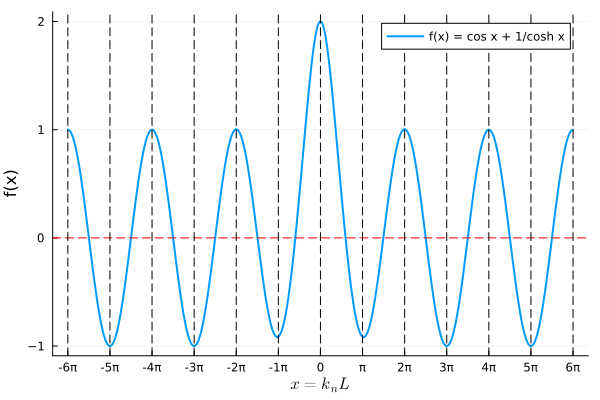

In [3]:
## Drawing the function for better guess in root finding

# label for k·pi
function pi_half_label(k::Integer)
    k == 0 && return "0"
    g   = gcd(k, 2)
    num = k ÷ g
    den = 2 ÷ g
    s = num == 1 ? "π" : num == -1 ? "-π" : "$(num)π"
    return den == 1 ? s : "$s/$den"
end

xs = range(-6*pi, 6*pi, length = 1000)
ys = f.(xs)

plot(xs, ys,
     label     = "f(x) = cos x + 1/cosh x",
     xlabel    = L"$x = k_n L$",
     ylabel    = "f(x)",
     linewidth = 2)

hline!([0], linestyle = :dash, color = :red, label = "")

xmin, xmax = xlims()
m = ceil(Int, xmin / π):floor(Int, xmax / π)

vline!(m .* π, linestyle = :dash, color = :black, label = "")

labels = [k == 0 ? "0" : k == 1 ? "π" : "$(k)π" for k in m]
xticks!(m .* π, labels)

#savefig("1_d_i_function.png")

In [4]:
## Defining Bisection method of root finding
function bisect(f, a, b)
    fa = f(a)
    for step in 1:200
        m  = (a + b) / 2
        fm = f(m)
        if sign(fm) == sign(fa)
            a  = m
            fa = fm
        else
            b = m
        end
        if b - a < 1e-14
            break
        end
    end
    return (a + b) / 2
end

bisect (generic function with 1 method)

From the plot of the function , we cas clearly see that there is one root between (n-1)pi to pi , in every pi interval.

I don't know what is the meaning of first 20 roots, i am taking only roots which are positive, not going to negative zone

In [5]:
## Taking the first 20 roots
N = 20
x = zeros(N)
for n in 1:N
    x[n] = bisect(f, (n - 1) * π, n * π)
end
x

20-element Vector{Float64}:
  1.87510406871196
  4.694091132974177
  7.85475743823761
 10.995540734875465
 14.137168391046472
 17.278759532088234
 20.420352251041248
 23.56194490180644
 26.703537555518302
 29.845130209102816
 32.986722862692844
 36.128315516282626
 39.26990816987241
 42.411500823462205
 45.553093477052
 48.6946861306418
 51.836278784231595
 54.97787143782138
 58.119464091411174
 61.26105674500097

In [6]:
## Printing a better table for the answer script
@printf("%2s  %12s\n", "n", "kₙL")
for n in 1:N
    @printf("%2d  %12.8f\n", n, x[n])
end

 n           kₙL
 1    1.87510407
 2    4.69409113
 3    7.85475744
 4   10.99554073
 5   14.13716839
 6   17.27875953
 7   20.42035225
 8   23.56194490
 9   26.70353756
10   29.84513021
11   32.98672286
12   36.12831552
13   39.26990817
14   42.41150082
15   45.55309348
16   48.69468613
17   51.83627878
18   54.97787144
19   58.11946409
20   61.26105675


In [7]:
## Making png for answerscript

h = 28 * (N + 2)                     
p = plot(xlims = (0, 2), ylims = (0, N + 1.6),
         axis = false, grid = false, legend = false,
         size = (320, h), dpi = 200)

# header
annotate!(0.5, N + 1, text(L"n", 13))
annotate!(1.4, N + 1, text(L"k_n L", 13))
plot!([0.1, 1.9], [N + 0.5, N + 0.5], color = :black, linewidth = 1.5)   

# rows
for n in 1:N
    y = N + 1 - n
    annotate!(0.5, y, text(string(n), 11))
    annotate!(1.4, y, text(@sprintf("%.8f", x[n]), 11))
end

savefig(p, "1_d_i_table.png")

"d:\\01_github\\Courses\\PLM_fall26\\ass2\\que1\\1_d_i_table.png"

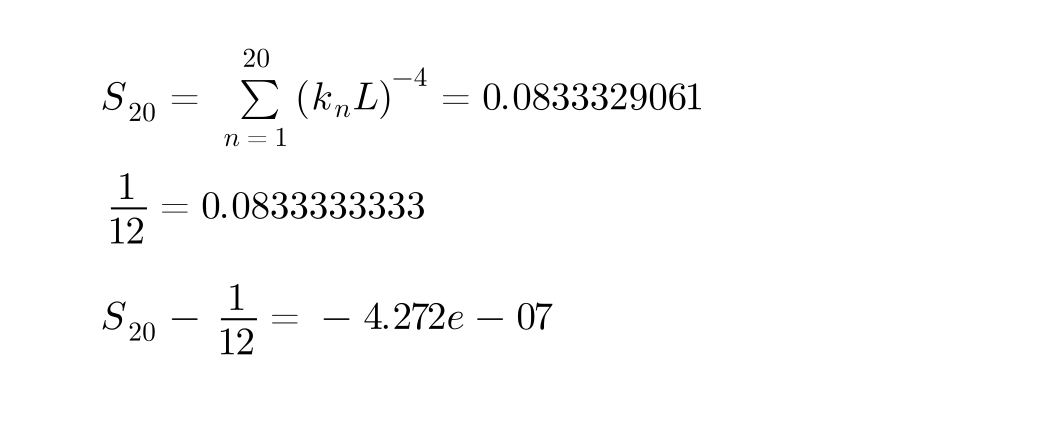

In [8]:
## Now i need to verify if sum matches or not

S20  = sum(x .^ -4)
ref  = 1/12
rel  = S20 - ref

line1 = latexstring("S_{20} = \\sum_{n=1}^{20} (k_n L)^{-4} = ", @sprintf("%.10f", S20))
line2 = latexstring("\\frac{1}{12} = ", @sprintf("%.10f", ref))
line3 = latexstring("S_{20} - \\frac{1}{12} = ", @sprintf("%.3e", rel))

p = plot(xlims = (0, 1), ylims = (0, 4),
         axis = false, grid = false, legend = false,
         size = (520, 220), dpi = 200)

annotate!(0.05, 3.2, text(line1, 13, :left))
annotate!(0.05, 2.0, text(line2, 13, :left))
annotate!(0.05, 0.8, text(line3, 13, :left))

savefig(p, "1_d_i_sum_check.png")
display("image/png", read("1_d_i_sum_check.png"))

In [9]:
### Now i want to see what fraction varaiance come from the first mode
frac1 = x[1]^-4 / (1/12)
@printf("Mode 1 carries %.2f %% of the tip variance\n", 100 * frac1)

Mode 1 carries 97.07 % of the tip variance


## 1.d.(ii)

W_n(s)=f(k_n*s)=f((k_n*L)*(s/L))=f(x_n,xi) ; x_n = k_n*L : root tha picks the mode , xi = s/L : position

In [10]:
## Defining the W, we already got it from analytics
function W(xi, xn) 
    chi = (cosh(xn) + cos(xn)) / (sinh(xn) + sin(xn))
    return cosh(xn * xi) - cos(xn * xi) - chi * (sinh(xn * xi) - sin(xn * xi)) ## Taking c1=-1
end

W (generic function with 1 method)

In [11]:
## checking if W_n(L)^=4 for all n or not 
for n in 1:5
    @printf("n = %d   W_n(L)^2 = %.6f\n", n, W(1.0, x[n])^2)
end

n = 1   W_n(L)^2 = 4.000000
n = 2   W_n(L)^2 = 4.000000
n = 3   W_n(L)^2 = 4.000000
n = 4   W_n(L)^2 = 4.000000
n = 5   W_n(L)^2 = 4.000000


In [12]:
## Now need to the normalisation
## Basic trapezoidal rule of integration or area under the curve
function trapz(t, f)
    total = 0.0
    for i in 1:length(t)-1
        total += (t[i+1] - t[i]) * (f[i] + f[i+1]) / 2
    end
    return total
end

trapz (generic function with 1 method)

In [13]:
xi = range(0, 1, length = 401) ## xi range will be 0 to 1 , because s range is 0 to L, xi = s/L

for n in 1:5
    area = trapz(xi, W.(xi, x[n]) .^ 2)
    @printf("n = %d   integral of W^2 = %.6f\n", n, area)
end

n = 1   integral of W^2 = 1.000006
n = 2   integral of W^2 = 1.000020
n = 3   integral of W^2 = 1.000033
n = 4   integral of W^2 = 1.000046
n = 5   integral of W^2 = 1.000059


In [14]:
function avg_y2(M, xi, x) ## we don't know the value of L^3/L_p , so it's in the unit of L^3/L_p
    total = zeros(length(xi))
    for n in 1:M
        total .+= W.(xi, x[n]) .^ 2 ./ x[n]^4
    end
    return total
end

avg_y2 (generic function with 1 method)

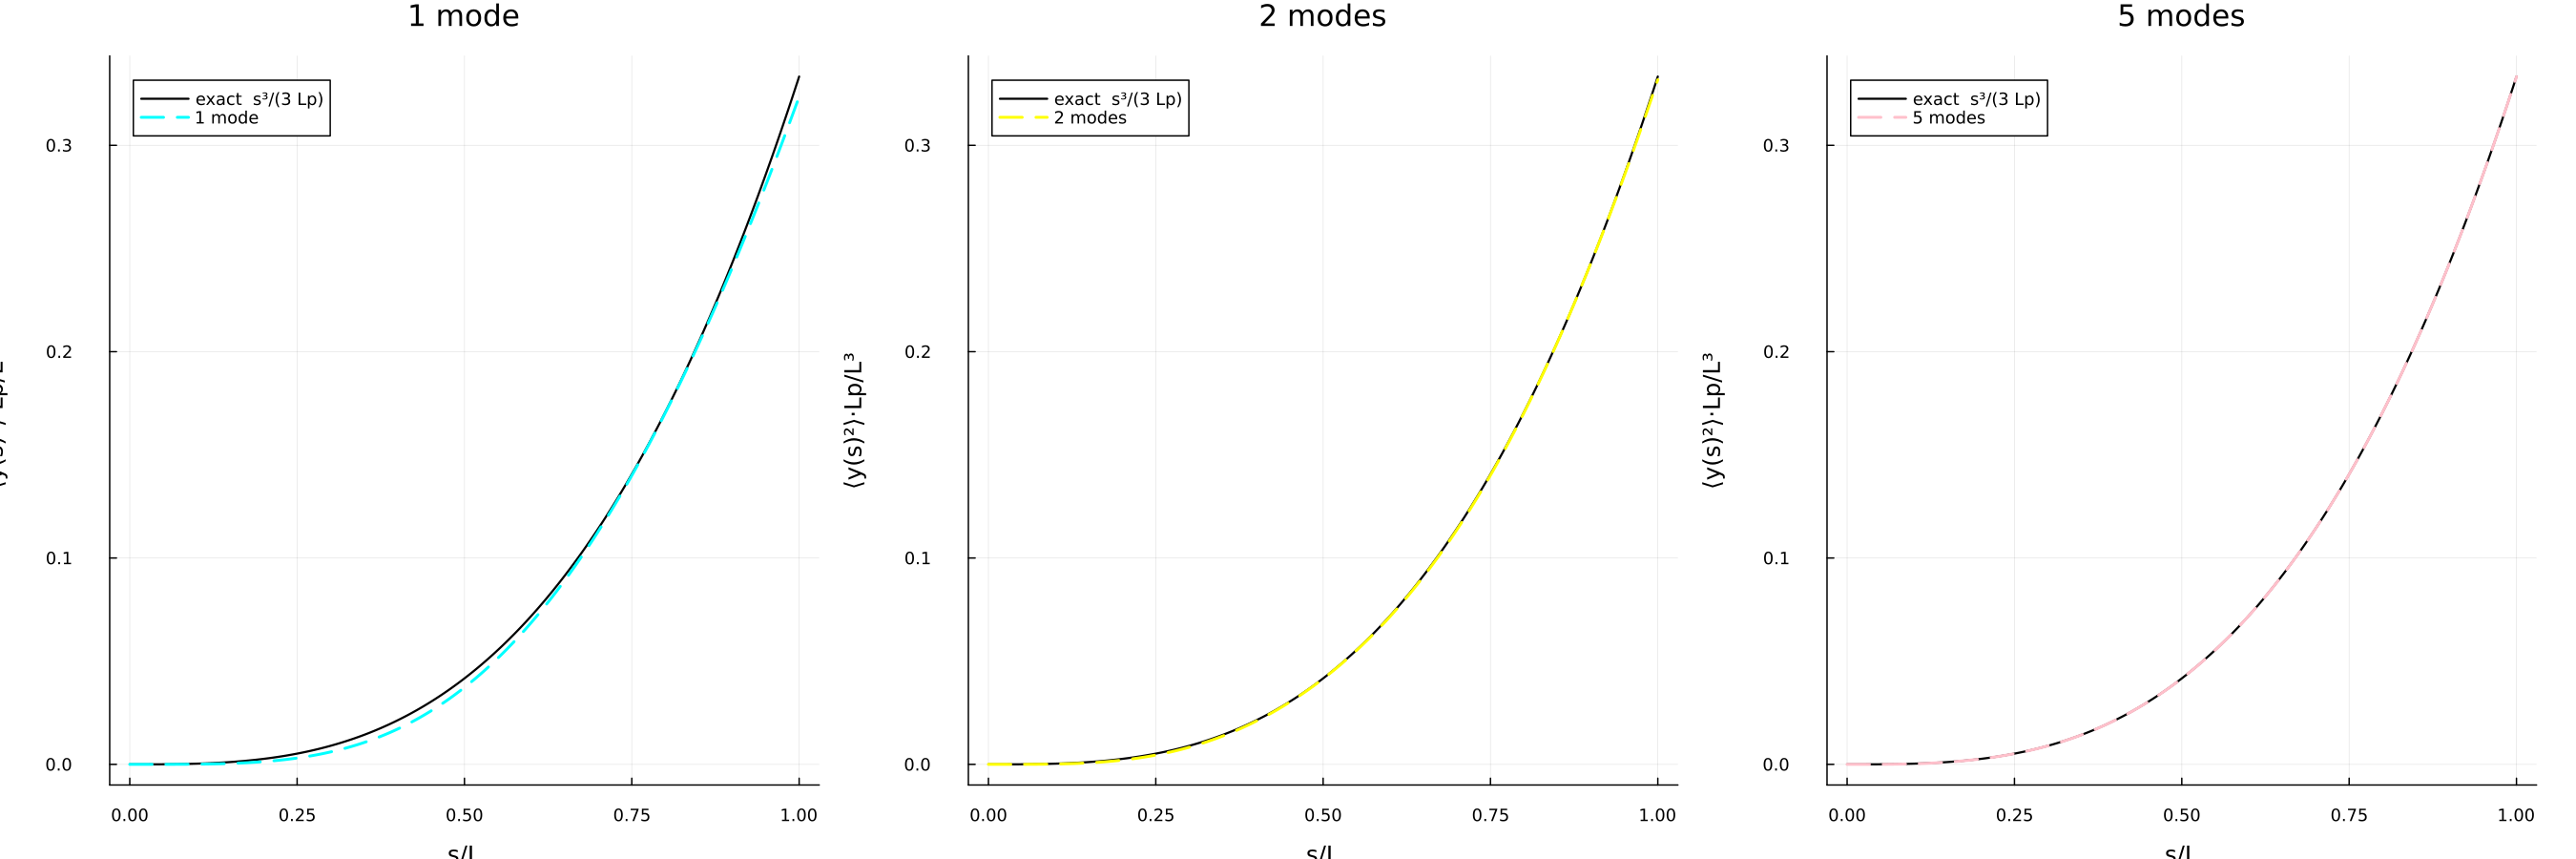

In [15]:

## From 1.b.(iii) expectation value of y^2 is calculated

exact = xi .^ 3 ./ 3

function mode_panel(nm, col)
    p = plot(xi, exact, label = "exact  s³/(3 Lp)", lw = 1.5, color = :black,
             xlabel = "s/L", ylabel = "⟨y(s)²⟩·Lp/L³",
             legend = :topleft, title = "$nm mode" * (nm == 1 ? "" : "s"))
    plot!(p, xi, avg_y2(nm, xi, x), label = "$nm mode" * (nm == 1 ? "" : "s"),
          lw = 2, ls = :dash, color = col)
    return p
end

p1 = mode_panel(1, :cyan)
p2 = mode_panel(2, :yellow)
p5 = mode_panel(5, :pink)

plt = plot(p1, p2, p5, layout = (1, 3), size = (1800, 600), dpi = 150,
           link = :y, margin = 5Plots.mm)

savefig(plt, "1_d_ii_y^2.png")
display("image/png", read("1_d_ii_y^2.png"))

## 1.d.(iii)

In [20]:
kL=x[1:10]

10-element Vector{Float64}:
  1.87510406871196
  4.694091132974177
  7.85475743823761
 10.995540734875465
 14.137168391046472
 17.278759532088234
 20.420352251041248
 23.56194490180644
 26.703537555518302
 29.845130209102816

In [22]:

L = 1.0
Lp_true = 100.0
var_a = L^3 ./ (Lp_true .* kL .^ 4)
sd_a = sqrt.(var_a)
S10 = sum(1 ./ kL .^ 4)
function estimate_Lp(Nsnap)
    a = randn(Nsnap, 10) .* sd_a'
    ytip = 2 .* vec(sum(a, dims=2))
    var_tip = sum(ytip .^ 2) / Nsnap
    return 4 * L^3 * S10 / var_tip
end 

Random.seed!(1)

@printf("true tip variance = %.6f L^2, L^3/(3 Lp) = %.6f L^2\n",
        4 * sum(var_a), L^3 / (3 * Lp_true))

@printf("one estimate with N = 1000: Lp = %.1f L (true value %.0f L)\n",
        estimate_Lp(1000), Lp_true)



true tip variance = 0.003333 L^2, L^3/(3 Lp) = 0.003333 L^2
one estimate with N = 1000: Lp = 97.8 L (true value 100 L)


In [ ]:
## Relative error
Ns = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]

trials = 500

rel_err = zeros(length(Ns))

for (i, Nsnap) in enumerate(Ns)
    errs = [(estimate_Lp(Nsnap) - Lp_true) / Lp_true for t in 1:trials]
    rel_err[i] = sqrt(sum(errs .^ 2) / trials)
    @printf("N = %5d: rms relative error = %.4f, sqrt(2/N) = %.4f\n",
            Nsnap, rel_err[i], sqrt(2 / Nsnap))
end  

N =    10: rms relative error = 0.7787, sqrt(2/N) = 0.4472
N =    20: rms relative error = 0.3851, sqrt(2/N) = 0.3162
N =    50: rms relative error = 0.2210, sqrt(2/N) = 0.2000
N =   100: rms relative error = 0.1470, sqrt(2/N) = 0.1414
N =   200: rms relative error = 0.1043, sqrt(2/N) = 0.1000
N =   500: rms relative error = 0.0615, sqrt(2/N) = 0.0632
N =  1000: rms relative error = 0.0450, sqrt(2/N) = 0.0447
N =  2000: rms relative error = 0.0315, sqrt(2/N) = 0.0316
N =  5000: rms relative error = 0.0211, sqrt(2/N) = 0.0200
N = 10000: rms relative error = 0.0144, sqrt(2/N) = 0.0141


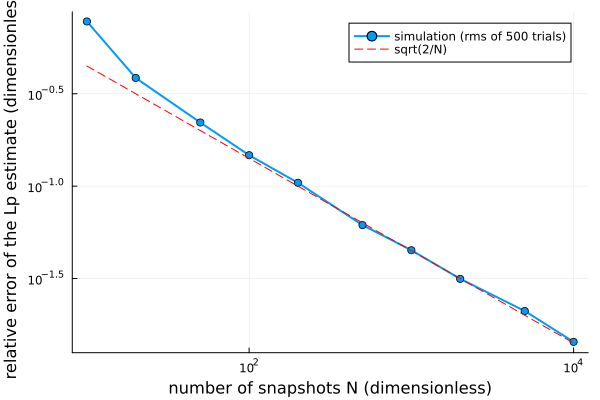

In [24]:

p_err = plot(Ns, rel_err, xscale=:log10, yscale=:log10, marker=:circle, linewidth=2,
             label="simulation (rms of 500 trials)", 
             xlabel="number of snapshots N (dimensionless)", 
             ylabel="relative error of the Lp estimate (dimensionless)",  
             legend=:topright)  

plot!(p_err, Ns, sqrt.(2 ./ Ns), linestyle=:dash, color=:red, label="sqrt(2/N)")

savefig(p_err, "1_d_iii_error.png")

p_err

## 1.(e)

In [25]:
kT = 4.1e-21
filaments = [("microtubule", 20e-6, 1e-3, 5e-3), 
             ("actin", 10e-6, 10e-6, 17e-6)]  
for (name, Lf, Lp_lo, Lp_hi) in filaments
    for Lp in (Lp_lo, Lp_hi)
        y_rms = sqrt(Lf^3 / (3 * Lp))
        th_rms = sqrt(Lf / Lp)
        @printf("%s, Lp = %.0f um: y_rms = %.2f um\n", name, Lp * 1e6, y_rms * 1e6)
        @printf("-> theta_rms = %.3f rad = %.1f deg, L/Lp = %.3f\n",
                th_rms, rad2deg(th_rms), Lf / Lp)  
    end  
end 

microtubule, Lp = 1000 um: y_rms = 1.63 um
-> theta_rms = 0.141 rad = 8.1 deg, L/Lp = 0.020
microtubule, Lp = 5000 um: y_rms = 0.73 um
-> theta_rms = 0.063 rad = 3.6 deg, L/Lp = 0.004
actin, Lp = 10 um: y_rms = 5.77 um
-> theta_rms = 1.000 rad = 57.3 deg, L/Lp = 1.000
actin, Lp = 17 um: y_rms = 4.43 um
-> theta_rms = 0.767 rad = 43.9 deg, L/Lp = 0.588


In [26]:
## Relaxation Times
mu = 1e-3
a_mt = 12.5e-9
L_mt = 20e-6
zp = 4 * pi * mu / log(L_mt / a_mt)
@printf("zeta_perp = %.3e Pa s\n", zp)
T_movie = 600.0
for Lp in (1e-3, 5e-3)
    A = kT * Lp
    tau1 = zp / (A * (kL[1] / L_mt)^4)
    tau2 = zp / (A * (kL[2] / L_mt)^4)
    N_ind = T_movie / tau1
    @printf("Lp = %.0f mm: tau1 = %.2f s, tau2 = %.3f s\n", Lp * 1e3, tau1, tau2)
    @printf("-> independent snapshots in 10 min = %.0f, precision on Lp = %.0f %%\n",
            N_ind, 100 * sqrt(2 / N_ind)) 
end  

zeta_perp = 1.703e-03 Pa s
Lp = 1 mm: tau1 = 5.38 s, tau2 = 0.137 s
-> independent snapshots in 10 min = 112, precision on Lp = 13 %
Lp = 5 mm: tau1 = 1.08 s, tau2 = 0.027 s
-> independent snapshots in 10 min = 558, precision on Lp = 6 %


In [27]:
blur(te, tau) = 2 * (tau / te)^2 * (te / tau - 1 + exp(-te / tau))
te = 0.05
for Lp in (1e-3, 5e-3)
    A = kT * Lp
    taus = [zp / (A * (kL[n] / L_mt)^4) for n in 1:10]
    b = blur.(te, taus)
    @printf("Lp = %.0f mm: variance kept, modes 1-4 = %.3f, %.3f, %.3f, %.3f\n",
            Lp * 1e3, b[1], b[2], b[3], b[4])  
    tip_factor = sum(b ./ kL .^ 4) / sum(1 ./ kL .^ 4)
    @printf("-> tip variance is reduced by a factor %.3f\n", tip_factor)
end 

Lp = 1 mm: variance kept, modes 1-4 = 0.997, 0.889, 0.468, 0.165
-> tip variance is reduced by a factor 0.991
Lp = 5 mm: variance kept, modes 1-4 = 0.985, 0.592, 0.130, 0.036
-> tip variance is reduced by a factor 0.971
